
# Fire and Smoke Detection Using YOLO

## Objective
The objective of this project is to train a YOLO object detection model to detect fire and smoke in images and videos using a custom dataset from Roboflow.

## Dataset
Fire and Smoke Detector Dataset - Version 14

## Model
Ultralytics YOLO


In [13]:

!pip install ultralytics roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 8.4 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: typer━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
    Found existing installation: typer 0.27.3━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
    Uninstalling typer-0.27.3:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
      Successfully uninstalled typer-0.27.3━━━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [ultralytics] [ultralytics]form]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [14]:

import os
import cv2
import torch
import matplotlib.pyplot as plt

from ultralytics import YOLO
from roboflow import Roboflow

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch Version: 2.11.0+cu130
GPU Available: True
GPU Name: Tesla T4



## Dataset Download

In this step, we connect to Roboflow and download the Fire and Smoke Detector dataset.

The selected dataset uses YOLO format, which contains images and corresponding annotation files.


In [15]:

from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
ROBOFLOW_API_KEY = secrets.get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# Select workspace and project
project = rf.workspace("gfo-fc1de").project("fire-and-smoke-detector-yykya")

# Download dataset version 14 in YOLO format
dataset = project.version(14).download("yolov8")

print("Dataset downloaded successfully!")
print("Dataset location:", dataset.location)


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-and-smoke-detector-14 in yolov8:: 100%|██████████| 11204/11204 [00:01<00:00, 10777.09it/s]

Dataset downloaded successfully!
Dataset location: /kaggle/working/fire-and-smoke-detector-14



## Dataset Inspection

In this step, we inspect the downloaded dataset structure, identify the training, validation, and testing folders, and examine the data.yaml configuration file.


In [16]:

dataset_path = dataset.location

print("Dataset Path:", dataset_path)
print("\nDataset Contents:")

for item in os.listdir(dataset_path):
    print(item)

print("\nData YAML Content:")

with open(os.path.join(dataset_path, "data.yaml"), "r") as file:
    print(file.read())


Dataset Path: /kaggle/working/fire-and-smoke-detector-14

Dataset Contents:
train
data.yaml
README.roboflow.txt
test
README.dataset.txt
valid

Data YAML Content:
names:
- fire
- smoke
nc: 2
roboflow:
  license: CC BY 4.0
  project: fire-and-smoke-detector-yykya
  url: https://universe.roboflow.com/gfo-fc1de/fire-and-smoke-detector-yykya/dataset/14
  version: 14
  workspace: gfo-fc1de
test: ../test/images
train: ../train/images
val: ../valid/images




## Dataset Structure and Configuration

The dataset is downloaded from Roboflow in YOLO format.

It contains two object classes:
- Fire (Class 0)
- Smoke (Class 1)

The dataset is divided into three main subsets:

1. Training Set: Used to train the YOLO model.
2. Validation Set: Used to evaluate model performance during training.
3. Testing Set: Used for final evaluation on unseen data.

The data.yaml file contains the dataset paths, class names, and number of classes. It allows YOLO to locate the images and understand the detection categories.

YOLO format includes images and corresponding annotation text files containing object class IDs and bounding box coordinates.


# Image Checking :

In [17]:

from glob import glob

for split in ["train", "valid", "test"]:
    images = glob(f"{dataset_path}/{split}/images/*")
    labels = glob(f"{dataset_path}/{split}/labels/*.txt")

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

# Display one sample annotation
sample_labels = glob(f"{dataset_path}/train/labels/*.txt")

if sample_labels:
    print("\nSample YOLO Annotation:")
    with open(sample_labels[0], "r") as file:
        print(file.read())



TRAIN
Images: 3940
Labels: 3940

VALID
Images: 1017
Labels: 1017

TEST
Images: 639
Labels: 639

Sample YOLO Annotation:
0 0.909375 0.334375 0.134375 0.66875


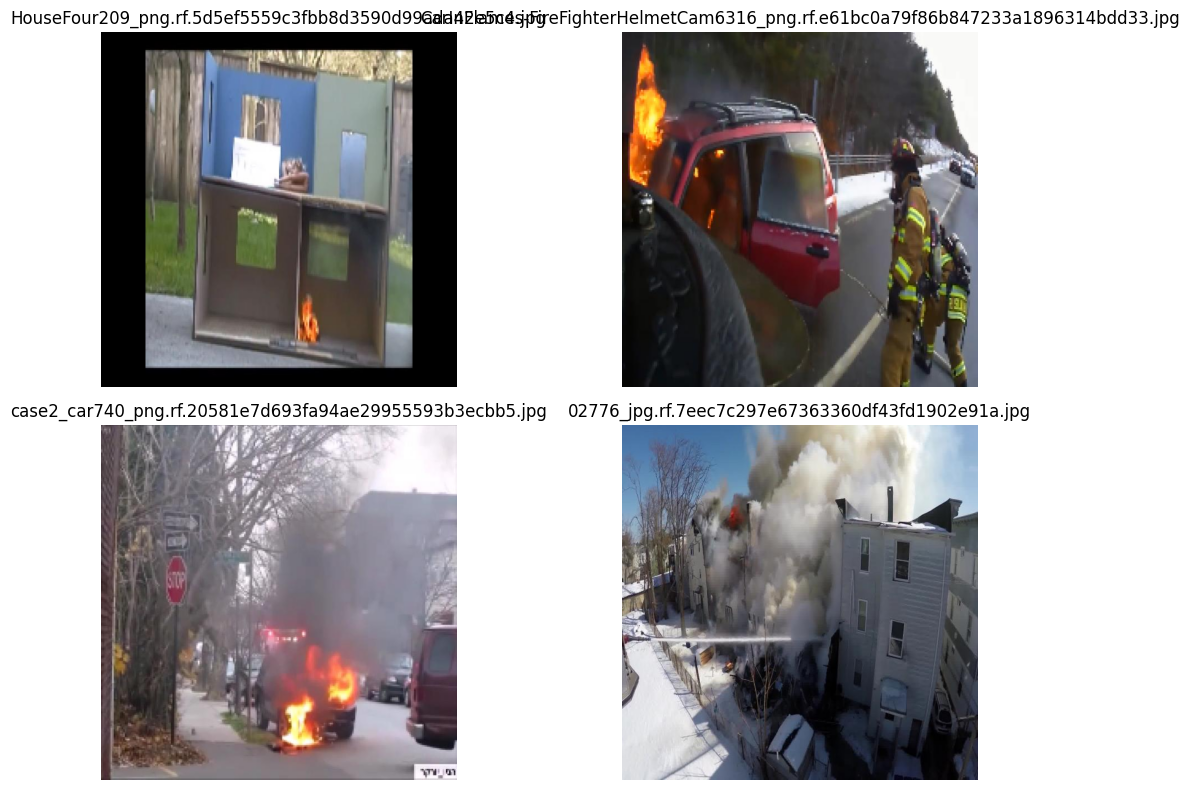

In [18]:

train_images = glob(f"{dataset_path}/train/images/*")

plt.figure(figsize=(12, 8))

for i, image_path in enumerate(train_images[:4]):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(os.path.basename(image_path))
    plt.axis("off")

plt.tight_layout()
plt.show()


# Checking Yaml paths:

In [19]:

import yaml

yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("Checking dataset paths:")

for split in ["train", "val", "test"]:
    path = os.path.join(dataset_path, data_config[split])

    print(f"{split}: {path}")
    print("Exists:", os.path.exists(path))


Checking dataset paths:
train: /kaggle/working/fire-and-smoke-detector-14/../train/images
Exists: False
val: /kaggle/working/fire-and-smoke-detector-14/../valid/images
Exists: False
test: /kaggle/working/fire-and-smoke-detector-14/../test/images
Exists: False


## so we should edit paths before work

In [20]:

data_config["train"] = "train/images"
data_config["val"] = "valid/images"
data_config["test"] = "test/images"

with open(yaml_path, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print("Dataset paths updated successfully!")


Dataset paths updated successfully!


# Check Yaml paths again 

In [21]:

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

for split in ["train", "val", "test"]:
    path = os.path.join(dataset_path, data_config[split])

    print(f"{split}: {path}")
    print("Exists:", os.path.exists(path))


train: /kaggle/working/fire-and-smoke-detector-14/train/images
Exists: True
val: /kaggle/working/fire-and-smoke-detector-14/valid/images
Exists: True
test: /kaggle/working/fire-and-smoke-detector-14/test/images
Exists: True


# Download Yolo

In [22]:

model = YOLO("yolov8n.pt")

print("YOLOv8 Nano model loaded successfully!")


YOLOv8 Nano model loaded successfully!



## 1. What a YOLO Dataset Format Contains

A standard YOLO dataset pairs every image file with a plain-text (.txt) annotation file of the exact same name (e.g., image1.jpg and image1.txt).
• Images: Standard image files (.jpg, .png, etc.) stored inside an images/ folder.
• Labels: Text files stored inside a parallel labels/ folder. If an image contains no objects, its .txt file is either left empty or omitted.
• Annotation Syntax: Each line in a .txt file represents one detected object using five space-separated numbers:
<class_id> <x_center> <y_center> <width> <height>
	• class_id: An integer starting at 0 that maps to the object's category.
	• x_center, y_center: The center coordinates of the bounding box.
	• width, height: The dimensions of the bounding box.
	• Normalization: All four coordinate values are normalized between 0 and 1 relative to the image's total width and height, allowing the model to resize images during training without losing label accuracy

    
## 2. The Role of the data.yaml File

The data.yaml file acts as the master blueprint that tells the YOLO training framework where to find the data and how to interpret the class IDs


## 3. Why Train, Validation, and Test Folders Are Important

Splitting your dataset into three distinct folders prevents the model from simply memorizing images and ensures it performs well on new, real-world data.

# Step 3: Train a YOLO Detection Model

In [23]:

results = model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    patience=10,
    project="/kaggle/working/fire_smoke_runs",
    name="yolov8n_fire_smoke"
)


Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fire-and-smoke-detector-14/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_fire_smoke, nbs=64, nms=Non

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      2.54G      2.047      2.357      1.966          5        640: 100% ━━━━━━━━━━━━ 247/247 9.2it/s 26.8s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.1it/s 5.3s0.2s
                   all       1016       1651      0.289      0.274       0.22     0.0799

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.54G      2.031       2.29       1.95         10        640: 100% ━━━━━━━━━━━━ 247/247 9.2it/s 27.0s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.0it/s 5.4s0.2s
                   all       1016       1651      0.366      0.333      0.286      0.108

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.55G      1.992       2.25      1.931         13        640: 100% ━━━━━━━━━━━━ 247/247 9.1it/s 27.2s0.2ss
                 Class     Ima


## What Detection Means in YOLO

In YOLO (You Only Look Once), object detection finds what objects are in an image and where they are located in a single pass of the neural network


## Why Start with a Small YOLO Model

Starting with a small model (such as a nano or small variant) lets you test your dataset, labels, and training setup quickly using less memory and compute.


## What Epochs Mean

An epoch is one complete pass through your entire training dataset. Training for more epochs gives the model more chances to learn patterns


## What Image Size Means

Image size (imgsz) is the resolution—such as 640 × 640 pixels—that images are resized to before entering the model


## What Happens During Model Training

• Forward pass: The model takes batches of images and predicts bounding boxes, classes, and confidence scores.
• Loss calculation: A loss function measures how far the model's predictions are from the true labels.
• Weight updates: An optimizer (like SGD or AdamW) adjusts the model's internal weights using the learning rate to reduce errors.
• Validation and repetition: The model is checked on validation data to track progress, and this cycle repeats across batches and epochs until training finishes or stops early

# Step 4: Inspect Training Results :

In [24]:
import os
from glob import glob
from IPython.display import Image, display

# Training output directory
results_path = "/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke"

# List all generated files
for file in glob(results_path + "/**/*", recursive=True):
    if os.path.isfile(file):
        print(file)

/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/args.yaml
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/train_batch9880.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/train_batch1.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/BoxR_curve.png
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/confusion_matrix_normalized.png
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/BoxF1_curve.png
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/val_batch1_labels.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/results.png
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/val_batch0_labels.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/confusion_matrix.png
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/train_batch0.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/val_batch0_pred.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/val_batch1_pred.jpg
/kaggle/working/fire_smoke_runs/yolov8n_fire_smoke/BoxPR_curve.png
/kaggle/working/fire_smoke

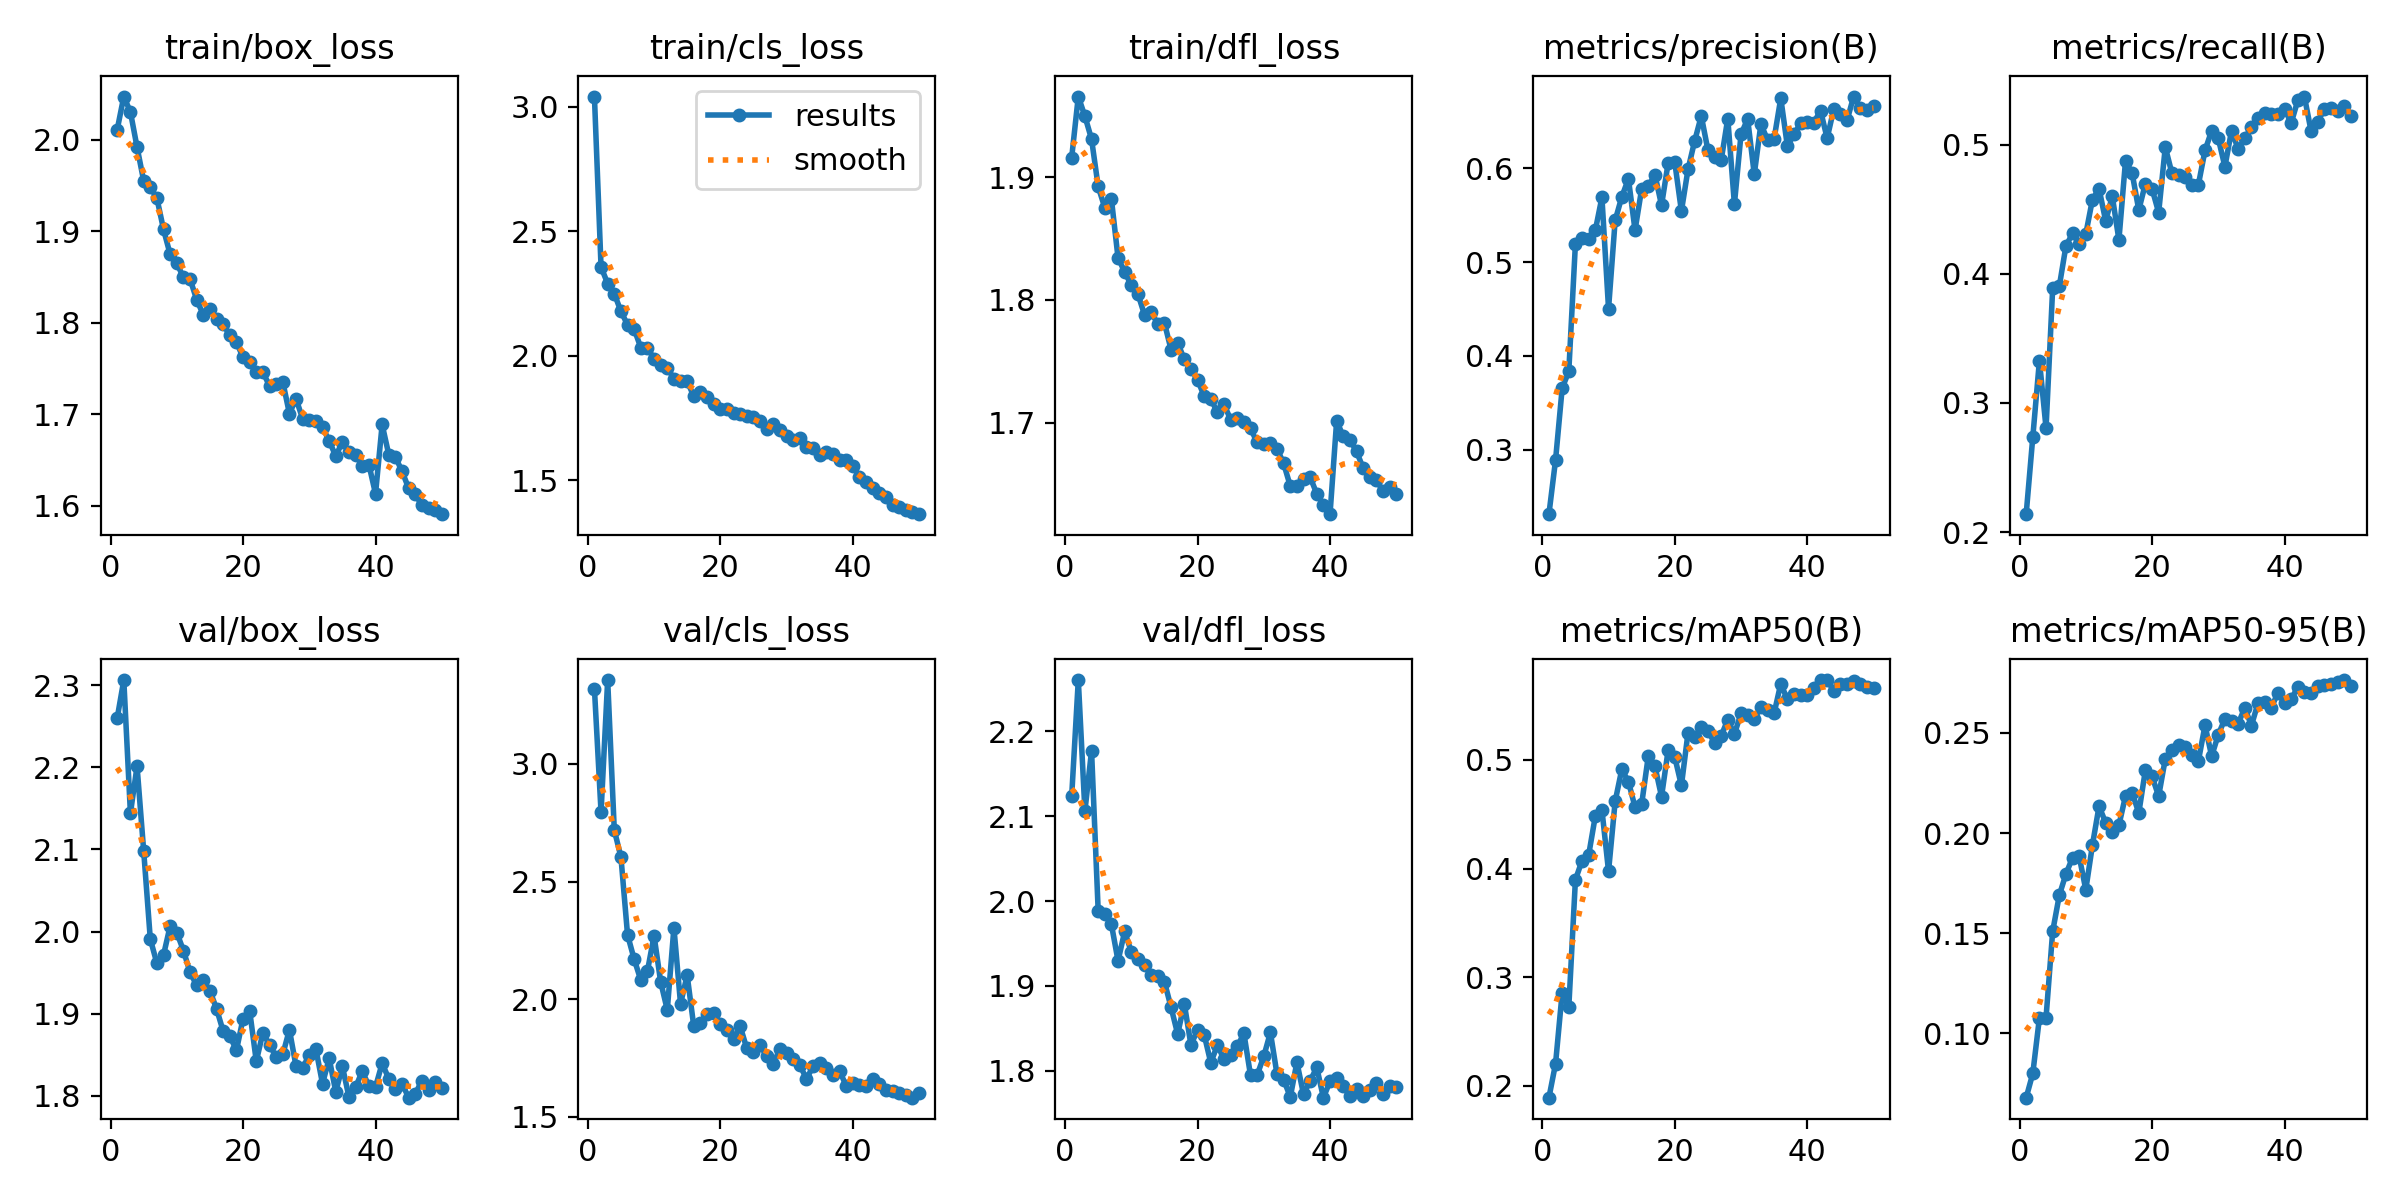

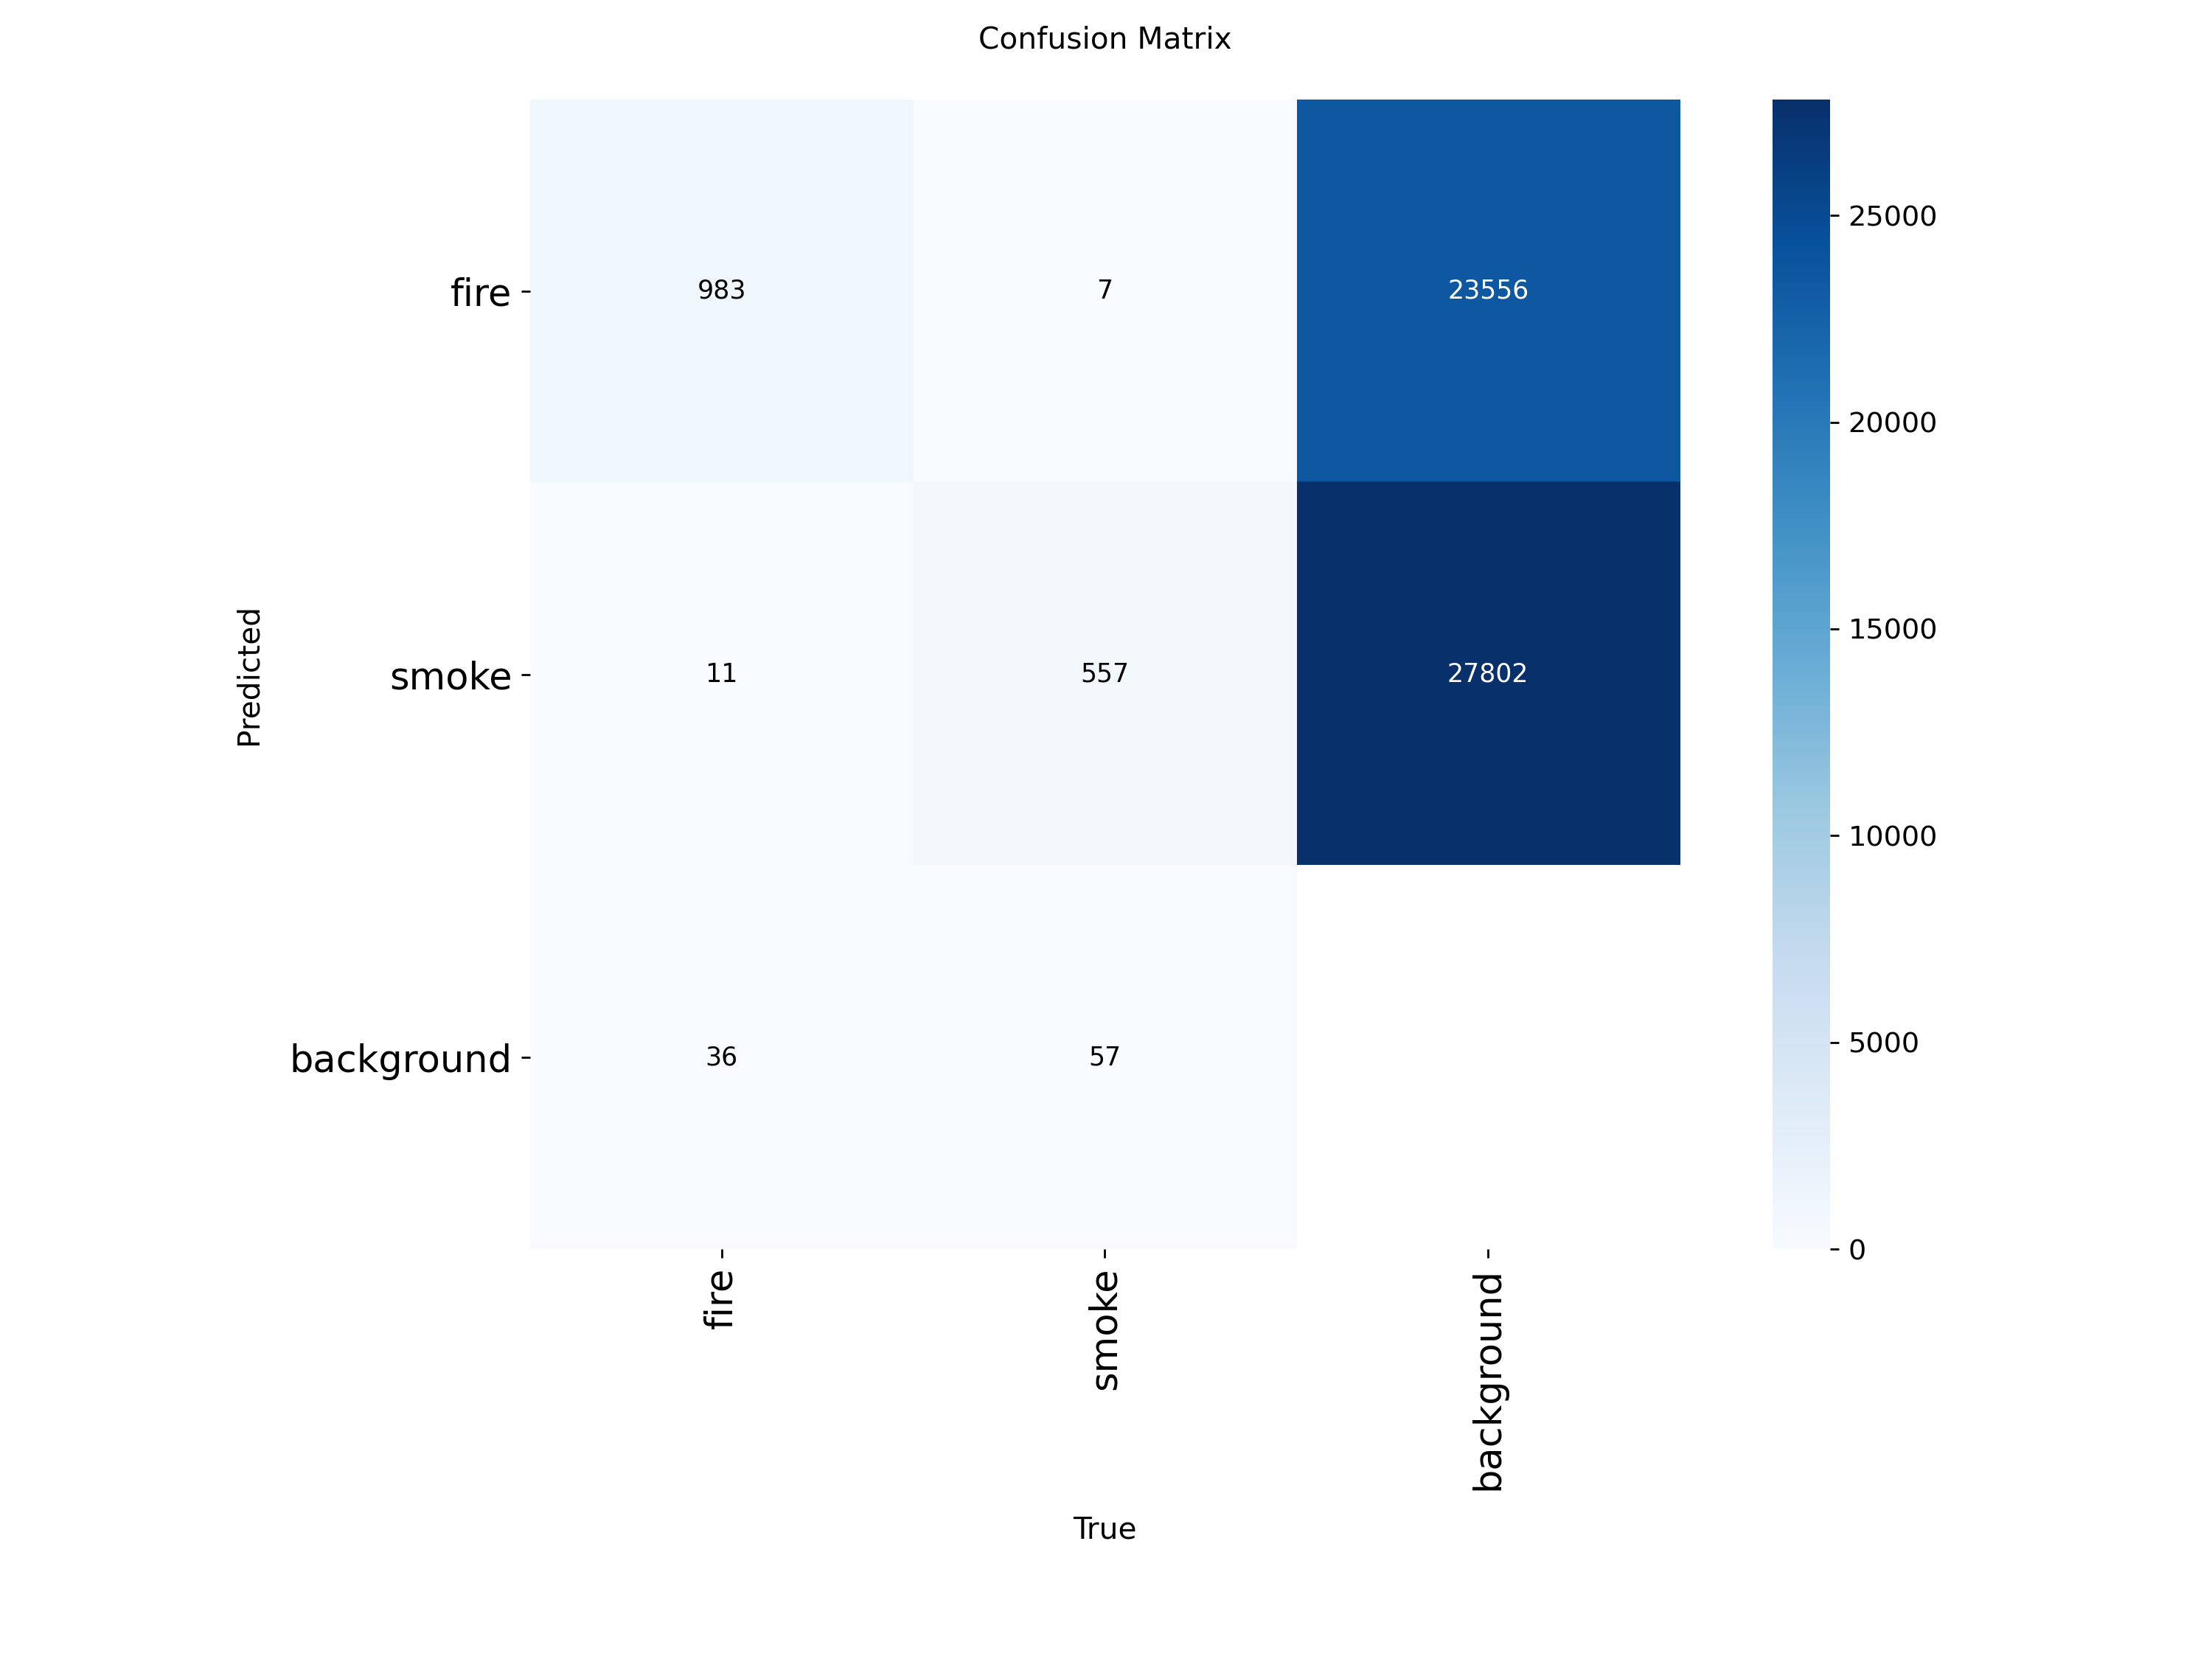

In [25]:
# Display training results
results_image = os.path.join(results_path, "results.png")

if os.path.exists(results_image):
    display(Image(filename=results_image))

# Display confusion matrix
confusion_matrix = os.path.join(results_path, "confusion_matrix.png")

if os.path.exists(confusion_matrix):
    display(Image(filename=confusion_matrix))

## Training Results and Evaluation

After completing the training process, YOLO generates several files to evaluate the model.

- best.pt: Contains the model weights with the best validation performance.
- last.pt: Contains the model weights from the final training epoch.
- results.png: Shows training and validation metrics across epochs.
- confusion_matrix.png: Shows correct and incorrect class predictions.

### Evaluation Metrics

- Precision: Measures how many detected objects were actually correct.
- Recall: Measures how many actual objects were successfully detected.
- mAP50: Measures object detection accuracy using an IoU threshold of 0.50.
- mAP50-95: Measures the average detection performance across IoU thresholds from 0.50 to 0.95.

## Step 5: Load Best.pt & Run Prediction on a Video 

In [26]:
best_model_path = os.path.join(
    results_path,
    "weights",
    "best.pt"
)

best_model = YOLO(best_model_path)

print("Best YOLO model loaded successfully!")

Best YOLO model loaded successfully!


In [27]:
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(
    accept=".mp4,.avi,.mov",
    multiple=False
)

display(uploader)

FileUpload(value=(), accept='.mp4,.avi,.mov', description='Upload')

In [28]:
uploaded_file = uploader.value

if isinstance(uploaded_file, dict):
    filename, file_info = next(iter(uploaded_file.items()))
    video_content = file_info["content"]
else:
    file_info = uploaded_file[0]
    filename = file_info["name"]
    video_content = file_info["content"]

video_path = os.path.join("/kaggle/working", filename)

with open(video_path, "wb") as f:
    f.write(bytes(video_content))

print("Video uploaded successfully!")
print("Video path:", video_path)
print("File exists:", os.path.exists(video_path))

Video uploaded successfully!
Video path: /kaggle/working/fire_smoke_test.mp4
File exists: True


In [30]:
prediction_results = best_model.predict(
    source=video_path,
    conf=0.25,
    save=True,
    project="/kaggle/working/fire_smoke_predictions",
    name="video_detection"
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/301) /kaggle/working/fire_smoke_test.mp4: 384x640 1 fire, 8.8ms
video 1/1 (frame 2/301) /kaggle/working/fire_smoke_test.mp4: 384x640 1 fire, 10.0ms
video 1/1 (frame 3/301) /kaggle/working/fire_smoke_test.mp4: 384x640 1 fire, 9.1ms
video 1/1 (frame 4/301) /kaggle/working/fire_smoke_test.mp4: 384x640 1 fire, 8.8ms
video 1/1 (frame 5/301) /kaggle/working/fire_smoke_test.mp4: 384x640 1 fire, 9.6ms
video 1/1 (frame 6/301) /kaggle/working/fir

In [40]:
output_videos = glob(
    "/kaggle/working/fire_smoke_predictions/video_detection/*.avi"
)

print(output_videos)

['/kaggle/working/fire_smoke_predictions/video_detection/fire_smoke_test.avi']
